Идея на таск с кузнечиком, из которого убрали S блок. Злоумышленник зашифровал базу данных, надо восстановить её
<details>
  <summary>Спойлеры</summary>
    идея строится на реализации госта через матричные операции (L блок в виде умножения матриц), можно внести все L преобразования и останется лишь ксор с каким-то 16 байтовым ключом, поскольку сигнатура шапки известа и более 16 байтов, то можно восстановить весь ключ и расшифровать все последующие блоки
</details>

In [2]:
from random import randbytes
M = [[207, 152, 116, 191, 147, 142, 242, 243, 10, 191, 246, 169, 234, 142, 77, 110],
     [110, 32, 198, 218, 144, 72, 137, 156, 193, 100, 184, 45, 134, 68, 208, 162],
     [162, 200, 135, 112, 104, 67, 28, 43, 161, 99, 48, 107, 159, 48, 227, 118],
     [118, 51, 16, 12, 28, 17, 214, 106, 166, 215, 246, 73, 7, 20, 232, 114],
     [114, 242, 107, 202, 32, 235, 2, 164, 141, 212, 196, 1, 101, 221, 76, 108],
     [108, 118, 236, 12, 197, 188, 175, 110, 163, 225, 144, 88, 14, 2, 195, 72],
     [72, 213, 98, 23, 6, 45, 196, 231, 213, 235, 153, 120, 82, 245, 22, 122],
     [122, 230, 78, 26, 187, 46, 241, 190, 212, 175, 55, 177, 212, 42, 110, 184],
     [184, 73, 135, 20, 203, 141, 171, 73, 9, 108, 42, 1, 96, 142, 75, 93],
     [93, 212, 184, 47, 141, 18, 238, 246, 8, 84, 15, 243, 152, 200, 127, 39],
     [39, 159, 190, 104, 26, 124, 173, 201, 132, 47, 235, 254, 198, 72, 162, 189],
     [189, 149, 94, 48, 233, 96, 191, 16, 239, 57, 236, 145, 127, 72, 137, 16],
     [16, 233, 208, 217, 243, 148, 61, 175, 123, 255, 100, 145, 82, 248, 13, 221],
     [221, 153, 117, 202, 151, 68, 90, 224, 48, 166, 49, 211, 223, 72, 100, 132],
     [132, 45, 116, 150, 93, 119, 111, 222, 84, 180, 141, 209, 68, 60, 165, 148],
     [148, 32, 133, 16, 194, 192, 1, 251, 1, 192, 194, 16, 133, 32, 148, 1]]


def mul_2(num: int) -> int:
    num <<= 1
    if num.bit_length() > 8:
        num ^= 0x1c3
    return num


def mul(a: int, b: int) -> int:
    result = 0
    while b:
        if b & 1:
            result ^= a
        a = mul_2(a)
        b >>= 1
    return result


def L(bytes_string: bytes) -> bytes:
    result = b''
    for row in M:
        local_byte = 0
        for i in range(16):
            local_byte ^= mul(row[i], bytes_string[i])
        result += bytes([local_byte])
    return result


def invL(bytes_string: bytes) -> bytes:
    result = b''
    for row in M[::-1]:
        local_byte = 0
        for i in range(16):
            local_byte ^= mul(row[-(i+1)], bytes_string[i])
        result += bytes([local_byte])
    return result


def xor(bytes_string: bytes, key: bytes) -> bytes:
    return bytes([a ^ b for a, b in zip(bytes_string, key)])

C = [L(bytes([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, i])) for i in range(1, 33)]

def key_extend(key: bytes) -> list[bytes]:
    k_1, k_2 = key[:16], key[16:]
    k = [k_1, k_2]
    for i in range(4):
        for j in range(8):
            k_2, k_1 = k_1, xor(L(xor(k_1, C[i*8 + j])), k_2)
        k+= [k_1, k_2]
    return k

def gost_encrypt_block(bytes_string: bytes, K: list[bytes]) -> bytes:
    for i in range(9):
        bytes_string = L(xor(bytes_string, K[i]))
    return xor(bytes_string, K[9])

def gost_decrypt_block(bytes_string: bytes, K: list[bytes]) -> bytes:
    for i in range(9):
        bytes_string = invL(xor(bytes_string, K[i]))
    return xor(bytes_string, K[9])

def pad(bytes_string: bytes, block_size: int) -> list[bytes]:
    padding_byte = block_size - len(bytes_string) % block_size
    bytes_string += bytes([padding_byte] * padding_byte)
    return [bytes_string[i:i+block_size] for i in range(0, len(bytes_string), block_size)]

def unpad(bytes_string: bytes) -> bytes:
    padding_byte = bytes_string[-1]
    return bytes_string[:-padding_byte]

def ECB_encrypt(text: bytes, K: list[bytes]) -> bytes:
    ct = b''
    text = pad(text, 16)
    for block in text:
        ct += gost_encrypt_block(block, K)
    return ct

def ECB_decrypt(ctext: bytes, K: list[bytes]) -> bytes:
    text = b''
    blocks = [ctext[i:i+16] for i in range(0, len(ctext), 16)]
    for block in blocks:
        text += gost_decrypt_block(block, K[::-1])
    text = unpad(text)
    return text

# key = randbytes(32)
# K = key_extend(key)
# with open("/home/gura/share/Database2.accdb", 'rb') as f:
#     text = f.read()
# ctext = ECB_encrypt(text, K)
# with open("../files/db.accdb", 'wb') as f:
#     f.write(ctext)


# Заметки по ходу написания задания


Матрицу для L преобразования можно найти довольно интересным способом, у нас получается уравнение
$M_{16*16} * x_{16*1} = b_{16*1}$,
где $M$ - матрица, соответствующая L преобразованию, $x$ - наша строка байтов, которую надо преобразовать, а $b$ - результат преобразования. Поскольку L преобразование у меня уже реализовано в обычном виде, я могу подавать любые вектора x(в рамках ограничений поля) на вход и получать соответствующие им вектора b, поэтому задача сводится к восстановлению матрицы из системы уравнений, где неизвестной переменной является сама матрица, надо только подобрать такие входные вектора x, чтобы из них можно было относительно просто восстановить матрицу, для этого можно подавать базисные вектора, то есть
$$
\begin{aligned}
x_1 &= (1, 0, 0, ..., 0), \\
x_2 &= (0, 1, 0, \dots, 0), \\
\vdots \\
x_{16} &= (0, 0, \dots, 1)
\end{aligned}
$$
Таким образом при умножении матрицы $M$ на $x_1$ мы получаем первый столбец матрицы, при умножении на $x_2$ - второй, и т.д.
``` python
s = long_to_bytes(1<< 120)
M = [[0 for _ in range(16)] for _ in range(16)]
for i in range(16):
    bytes_string = L(s)
    for j in range(16):
        M[j][i] = bytes_string[j]
    s = b'\x00'*(i+1) + long_to_bytes(bytes_to_long(s) >> 8)
```
Данная матрица была протестирована на случайных 16 байтных векторах, умножение на неё полностью совпадает с преобразованием L в итоговом результате\
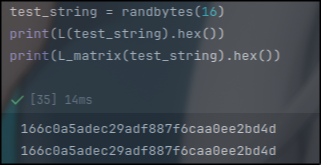

Точно также можно найти и матрицу для обратного преобразования.

Однако есть и иной путь, для нахождения данных матриц. Рассмотрим преобразование R. Это линейное преобразование, которое сдвигает байты вправо, а на место первого байта ставит линейную комбинацию прошлой последовательности. Таким образом это преобразование можно записать в виде умножения сопровождающей матрицы на вектор, гед в качестве вектора выступает само сообщение, которое преобразовывают. Довольно очевидно, что в качестве сопровождающей матрицы следует использовать матрицу
$$
R =
\begin{pmatrix}
148 & 32 & 133 & 16 & 194 & 192 & 1 & 251 & 1 & 192 & 194 & 16 & 133 & 32 & 148 & 1 \\
1 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 1 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 1 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 1 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 1 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 1 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 1 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 1 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1 & 0 \\
\end{pmatrix}
$$
Т.к. L преобразование - 16 раз подряд применённое R преобразование, то для нахождения матрицы $M$, необходимо возвести матрицу $R$  в 16 степень, то есть $M = R^{16}$. У сопровождающих матриц есть одна особенность, если коэффициенты сопровождаемого многочлена палиндромны, то есть $c_i = c_{n−1−i}$, то обратной ей будет матрица $R^{-1} = JRJ$, где
$$
J =
\begin{bmatrix}
0 & 0 & \dots & 0 & 1 \\
0 & 0 & \dots & 1 & 0 \\
\vdots  & \vdots  & \ddots & \vdots \\
0 & 1 & \dots & 0 & 0 \\
1 & 0 & \dots & 0 & 0
\end{bmatrix}
$$
Таким образом, $M^{-1} = (R^{-1})^{16} = (JRJ)^{16} = JR^{16}J = JMJ$, отсюда вытекает, что $M^{-1}$ и $M$ это одна и та же матрица, только повёрнутая на 180 градусов, то есть центросимметричная (проще говоря, все строки идут в обратном порядке, а внутри строк все элементы также идут в обратном порядке (первая строка станет последней, первый элемент каждой строки станет последним и т.д.)). Благодаря этому можно не задавать в коде $M^{-1}$, достаточно обращаться к элементам матрицы $M$ в обратном порядке
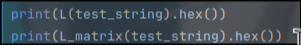
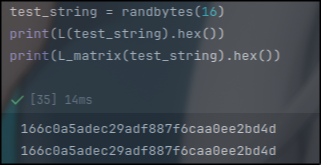

На случай будущих проверок, сохраню в данном разделе различные значения
```
B = [[148, 32, 133, 16, 194, 192, 1, 251, 1, 192, 194, 16, 133, 32, 148, 1],
     [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
     [0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
     [0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
     [0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
     [0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
     [0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
     [0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
     [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0],
     [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0],
     [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0],
     [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0],
     [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0],
     [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0],
     [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0],
     [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0]]
def matmul(A, B):
    n = len(A)
    C = [[0]*n for _ in range(n)]
    for i in range(n):
        for j in range(n):
            s = 0
            for k in range(n):
                s ^= mul(A[i][k], B[k][j])
            C[i][j] = s
    return C
```

# Решение

Ранее во время сдачи модуля по блочным шифрам я вывел, формулу, показывающую как выглядит шифровании кузнечика без блока замены, оттуда следует, что $k = c + M^9m $, где $c$ - шифротекст, $m$ - открытый текст, $M$ - L преобразование в виде умножения на матрицу, $k$ - результирующий ключ(совокупность раундовых ключей, с которой в итоге происходит ксор). Мы знаем, что у нас шифруется файл формата ".accdb", быстрый поиск в интернете даёт нам начальную сигнатуру файла "00 01 00 00 53 74 61 6E 64 61 72 64 20 41 43 45 20 44 42", что даёт нам первые 19 байтов открытого текста. Шифрование в кузнечике идёт блоками по 16 байт, следовательно мы можем полностью восстановить ключ по формуле, после чего применить его к последующим блокам. Далее несложно вывести, что $m = M^{-9}(c+k)$

In [3]:
def matmul(A, B):
    n = len(A)
    C = [[0]*n for _ in range(n)]
    for i in range(n):
        for j in range(n):
            s = 0
            for k in range(n):
                s ^= mul(A[i][k], B[k][j])
            C[i][j] = s
    return C


M_9 = [[int(i==j) for j in range(16)] for i in range(16)]
for i in range(9):
    M_9 = matmul(M_9, M)


def L9(bytes_string: bytes) -> bytes:
    result = b''
    for row in M_9:
        local_byte = 0
        for i in range(16):
            local_byte ^= mul(row[i], bytes_string[i])
        result += bytes([local_byte])
    return result

def invL9(bytes_string: bytes) -> bytes:
    result = b''
    for row in M_9[::-1]:
        local_byte = 0
        for i in range(16):
            local_byte ^= mul(row[-(i+1)], bytes_string[i])
        result += bytes([local_byte])
    return result
ct1 = bytes.fromhex("24194dd3c332fa0fb68bc0221195226d")
with open("../files/db.accdb", 'rb') as f:
    ct = f.read()
ct = bytes.fromhex('f59d7572dd3b6f3420d4e88bb7959459')
part_text =  bytes.fromhex('b71f70d91e6513a64ee151e130b870fb')
k = xor(ct1, L9(part_text))
print(part_text)

def attack_gost_decrypt_block(ctext: bytes, k: bytes) -> bytes:
    return invL9(xor(ctext, k))


def ECB_decrypt(ctext: bytes, k: bytes) -> bytes:
    text = b''
    blocks = [ctext[i:i+16] for i in range(0, len(ctext), 16)]
    for block in blocks:
        text += attack_gost_decrypt_block(block, k)
    print(text)
    text = unpad(text)
    return text
probably_text = ECB_decrypt(ct, k)
print(probably_text)

# with open("../files/db_decrypt.accdb", 'wb') as f:
#     f.write(probably_text)

b'\xb7\x1fp\xd9\x1ee\x13\xa6N\xe1Q\xe10\xb8p\xfb'
b'flag{of_non_lin}'
b''
